# **FORMATOS EXCLUIDOS DEL ENTRENAMIENTO**

Durante el preprocesamiento se decidió restringir el entrenamiento a imágenes en formato **6×2 horizontal** (hoja horizontal y vertical), dado que los demás formatos presentaban distribución desigual entre clases, lo que podría introducir sesgos. En este notebook, se evalúa el comportamiento de los modelos entrenados sobre las imágenes **excluidas de ese filtrado**: formatos 6×2 vertical y 12×1 (todas variantes). Las imágenes del subconjunto "raras" (fotografías de papel) se excluyen también de este análisis por no ser imágenes digitales. 

El análisis realizado en este notebook es complementario y no forma parte del informe final presentado.

In [1]:
import os, gc, subprocess
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as mpl_cm
import seaborn as sns
import tensorflow as tf
from pathlib import Path
from PIL import Image
from pdf2image import convert_from_path
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)
    print(f'GPU: {gpus[0].name}')
else:
    print('CPU')

CPU


In [3]:
REPO_ROOT  = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'],
                                  capture_output=True, text=True).stdout.strip())
DATA_RAW   = Path(r'C:\Users\Victoria\Desktop\Datos ICBA')
CNN_DIR    = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 2' / 'Modelo CNN'
CVNXT_DIR  = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 2' / 'Modelo Preentrenado'

CLASSES          = ['Am', 'HTA', 'EAo', 'MCH']
DPI              = 200
MODEL_INPUT_SIZE = (352, 192)   # ancho × alto, igual que en la app (config.py)

# Capas usadas por Grad-CAM (igual que en ICBApp/model_interface.py)
CNN_GRADCAM_LAYER   = 're_lu_7'
CVNXT_GRADCAM_LAYER = 'convnext_tiny_stage_2_block_8_identity'

ENSEMBLE_WEIGHTS = {'cnn': 0.4, 'cvnxt': 0.6}

EXCLUDED_LAYOUTS = [
    '6x2 vertical (hoja vertical)',
    '12x1 horizontal (hoja horizontal)',
    '12x1 horizontal (hoja vertical)',
    '12x1 vertical (hoja vertical)',
]

In [4]:
import cv2

def crop_ecg_array(img_bgr):
    """
    Recorta márgenes detectando la grilla del ECG vía Hough.
    Réplica de _crop_ecg() en ICBApp/model_interface.py, que a su vez
    replica crop_ecg() del notebook 2- Preprocesamiento.
    """
    height, width = img_bgr.shape[:2]
    scale  = 2.0 if min(height, width) < 1000 else 1.0
    img_det = cv2.resize(img_bgr, None, fx=scale, fy=scale,
                         interpolation=cv2.INTER_CUBIC) if scale != 1.0 else img_bgr

    h_det   = img_det.shape[0]
    edges   = cv2.Canny(cv2.cvtColor(img_det, cv2.COLOR_BGR2GRAY), 50, 150)
    lines   = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=60,
                               minLineLength=int(h_det*0.30), maxLineGap=15)

    candidates = []
    if lines is not None:
        for x1, y1, x2, y2 in lines.reshape(-1, 4):
            if 85 < abs(np.arctan2(y2-y1, x2-x1)*180/np.pi) < 95:
                candidates.append((x1, y1, x2, y2))

    if not candidates:
        return img_bgr

    pad   = int(h_det * 0.01)
    y_top = max(0, int(np.median([min(l[1],l[3]) for l in candidates])) - pad)
    y_bot = min(h_det, int(np.median([max(l[1],l[3]) for l in candidates])) + pad)
    return img_bgr[int(y_top/scale):int(y_bot/scale), :]


def preprocess_pil(pil_img, model_input_size):
    """
    Crop + grayscale + resize a model_input_size (ancho, alto).
    Réplica de _preprocess_gray() en ICBApp/model_interface.py.
    Devuelve (H, W) uint8.
    """
    img_bgr  = np.array(pil_img.convert('RGB'))[:, :, ::-1]
    cropped  = crop_ecg_array(img_bgr)
    gray_pil = Image.fromarray(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB)).convert('L')
    return np.array(gray_pil.resize(model_input_size, Image.LANCZOS))


def load_excluded_images(data_raw, classes, excluded_layouts, dpi=200, model_input_size=(352,192)):
    imgs_gray = []   # (H, W, 1) float32 [0,1]  — entrada CNN
    imgs_rgb  = []   # (H, W, 3) uint8           — entrada CVNXT
    imgs_disp = []   # (H, W) uint8              — visualización
    y_true    = []
    names     = []
    layouts   = []

    for label_idx, cls in enumerate(classes):
        for layout in excluded_layouts:
            layout_dir = data_raw / cls / layout
            if not layout_dir.exists():
                continue
            for f in sorted(layout_dir.iterdir()):
                ext = f.suffix.lower()
                pil_pages = []
                if ext == '.pdf':
                    pil_pages = convert_from_path(str(f), dpi=dpi)
                elif ext in ('.jpg', '.jpeg', '.png'):
                    pil_pages = [Image.open(f)]
                else:
                    continue

                for page in pil_pages:
                    gray = preprocess_pil(page, model_input_size)   # (192, 352)
                    imgs_gray.append(gray[:, :, np.newaxis].astype(np.float32) / 255.0)
                    imgs_rgb.append(np.stack([gray]*3, axis=-1))
                    imgs_disp.append(gray)
                    y_true.append(label_idx)
                    names.append(f'{cls}/{layout}/{f.name}')
                    layouts.append(layout)

    return (np.array(imgs_gray, dtype=np.float32),
            np.array(imgs_rgb,  dtype=np.uint8),
            imgs_disp,
            np.array(y_true, dtype=np.int32),
            names, layouts)


print('Cargando y preprocesando imágenes excluidas...')
imgs_gray, imgs_rgb, imgs_disp, y_true, img_names, img_layouts = \
    load_excluded_images(DATA_RAW, CLASSES, EXCLUDED_LAYOUTS, DPI, MODEL_INPUT_SIZE)

print(f'\nTotal imágenes: {len(y_true)}')
for i, cls in enumerate(CLASSES):
    print(f'  {cls}: {(y_true == i).sum()}')

Cargando y preprocesando imágenes excluidas...

Total imágenes: 132
  Am: 85
  HTA: 25
  EAo: 5
  MCH: 17


In [5]:
# Tabla de distribución por layout × clase
records = [{'layout': l, 'clase': CLASSES[y]} for l, y in zip(img_layouts, y_true)]
df_stats = pd.DataFrame(records)
pivot = df_stats.groupby(['layout', 'clase']).size().unstack(fill_value=0)
pivot = pivot.reindex(columns=CLASSES, fill_value=0)
pivot['TOTAL'] = pivot.sum(axis=1)
pivot.loc['TOTAL'] = pivot.sum()
print(pivot.to_string())

clase                              Am  HTA  EAo  MCH  TOTAL
layout                                                     
12x1 horizontal (hoja horizontal)  12    1    0    0     13
12x1 horizontal (hoja vertical)    24    8    5    5     42
12x1 vertical (hoja vertical)       7    2    0    5     14
6x2 vertical (hoja vertical)       42   14    0    7     63
TOTAL                              85   25    5   17    132


## **Predicciones de los modelos**

In [6]:
# Ahora todas las imágenes tienen el mismo tamaño → se puede usar tf.data con batch
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 16

ds_gray = tf.data.Dataset.from_tensor_slices(imgs_gray).batch(BATCH_SIZE).prefetch(AUTOTUNE)
ds_rgb  = tf.data.Dataset.from_tensor_slices(imgs_rgb ).batch(BATCH_SIZE).prefetch(AUTOTUNE)

model_cvnxt = tf.keras.models.load_model(CVNXT_DIR / 'CVNXT-FINAL.keras')
model_cnn   = tf.keras.models.load_model(CNN_DIR   / 'CNN-FINAL.keras')

cvnxt_probs = model_cvnxt.predict(ds_rgb,  verbose=1)
cnn_probs   = model_cnn.predict(ds_gray, verbose=1)

del model_cvnxt; tf.keras.backend.clear_session(); gc.collect()

cnn_preds   = np.argmax(cnn_probs,   axis=1)
cvnxt_preds = np.argmax(cvnxt_probs, axis=1)
ens_probs   = ENSEMBLE_WEIGHTS['cnn'] * cnn_probs + ENSEMBLE_WEIGHTS['cvnxt'] * cvnxt_probs
ens_preds   = np.argmax(ens_probs, axis=1)

ba_cnn   = balanced_accuracy_score(y_true, cnn_preds)
ba_cvnxt = balanced_accuracy_score(y_true, cvnxt_preds)
ba_ens   = balanced_accuracy_score(y_true, ens_preds)

print(f'Bal. Acc  CNN   : {ba_cnn:.4f}')
print(f'Bal. Acc  CVNXT : {ba_cvnxt:.4f}')
print(f'Bal. Acc  Ens   : {ba_ens:.4f}')


9/9 ━━━━━━━━━━━━━━━━━━━━ 47s 5s/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 560ms/step
Bal. Acc  CNN   : 0.4229
Bal. Acc  CVNXT : 0.5435
Bal. Acc  Ens   : 0.5100


## **Métricas y Matrices de Confusión**

Modelo,Balanced Accuracy,Accuracy,Precision,Recall,F1-macro,F1-Am,F1-HTA,F1-EAo,F1-MCH
CNN-FINAL,0.4229,0.5379,0.3761,0.4229,0.3793,0.7105,0.4528,0.2000,0.1538
CVNXT-FINAL,0.5435,0.4545,0.4104,0.5435,0.4127,0.5496,0.4444,0.3810,0.2759
Ensamble 40/60,0.5100,0.4773,0.3978,0.5100,0.3995,0.6143,0.4400,0.3478,0.1961


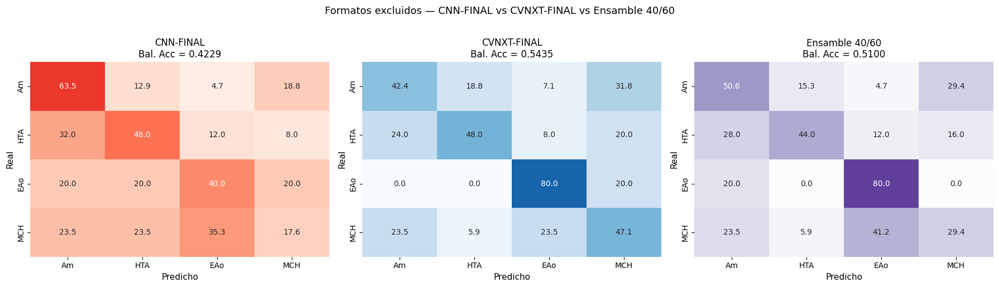

In [7]:
# ── Tabla resumen 3 modelos ───────────────────────────────────────────────────
rows = []
for name, preds, probs, ba in [
    ('CNN-FINAL',      cnn_preds,   cnn_probs,   ba_cnn),
    ('CVNXT-FINAL',    cvnxt_preds, cvnxt_probs, ba_cvnxt),
    ('Ensamble 40/60', ens_preds,   ens_probs,   ba_ens),
]:
    rep = classification_report(y_true, preds, target_names=CLASSES,
                                output_dict=True, zero_division=0)
    rows.append({
        'Modelo':            name,
        'Balanced Accuracy': round(ba, 4),
        'Accuracy':          round((preds == y_true).mean(), 4),
        'Precision':         round(float(np.mean([rep[c]['precision'] for c in CLASSES])), 4),
        'Recall':            round(float(np.mean([rep[c]['recall']    for c in CLASSES])), 4),
        'F1-macro':          round(rep['macro avg']['f1-score'], 4),
        'F1-Am':             round(rep['Am']['f1-score'],  4),
        'F1-HTA':            round(rep['HTA']['f1-score'], 4),
        'F1-EAo':            round(rep['EAo']['f1-score'], 4),
        'F1-MCH':            round(rep['MCH']['f1-score'], 4),
    })

df_summary = pd.DataFrame(rows)
mcols = [c for c in df_summary.columns if c != 'Modelo']
display(df_summary.style.format({c: '{:.4f}' for c in mcols}).hide(axis='index'))

# ── Subplot 3 matrices de confusión ──────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, preds, name, ba, cmap in zip(
    axes,
    [cnn_preds,   cvnxt_preds,   ens_preds],
    ['CNN-FINAL', 'CVNXT-FINAL', 'Ensamble 40/60'],
    [ba_cnn,      ba_cvnxt,      ba_ens],
    ['Reds',      'Blues',       'Purples'],
):
    cm_mat = confusion_matrix(y_true, preds, normalize='true') * 100
    sns.heatmap(cm_mat, annot=True, fmt='.1f', cmap=cmap,
                xticklabels=CLASSES, yticklabels=CLASSES,
                vmin=0, vmax=100, ax=ax, cbar=False)
    ax.set_xlabel('Predicho', fontsize=11)
    ax.set_ylabel('Real',     fontsize=11)
    ax.set_title(f'{name}\nBal. Acc = {ba:.4f}', fontsize=12)

plt.suptitle('Formatos excluidos — CNN-FINAL vs CVNXT-FINAL vs Ensamble 40/60',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

Como era de esperarse, el desempeño sobre los formatos excluidos fue considerablemente inferior al obtenido sobre el formato 6×2 horizontal utilizado durante el entrenamiento. El ensamble alcanzó una BA de 0,5100, frente a 0,7809 en el conjunto de prueba original, mientras que CNN-FINAL y CVNXT-FINAL obtuvieron valores de 0,4229 y 0,5435, respectivamente.

La caída fue más marcada en CNN-FINAL. Una posible explicación es que esta arquitectura aprendió sus representaciones exclusivamente a partir de imágenes en formato 6×2, tanto en el preentrenamiento sintético como en el ajuste sobre el dataset ICBA, por lo que dispone de menos características generales que le permitan adaptarse a una disposición distinta de las derivaciones. CVNXT-FINAL, en cambio, parte de representaciones aprendidas sobre ImageNet, lo que podría otorgarle una mayor robustez frente a estos cambios.


## **Grad-CAM**

In [8]:
def build_grad_models(model_cnn, model_cvnxt, cnn_layer, cvnxt_layer):
    """
    Construye los modelos auxiliares para Grad-CAM.
    Réplica exacta de _get_grad_models() en ICBApp/model_interface.py,
    que a su vez replica la celda 'Construcción de modelos Grad-CAM'
    del notebook 24- Grad-CAM.
    Los backbones están anidados, por eso hay que reconstruir el grafo.
    """
    # CNN
    bb_cnn = model_cnn.get_layer('cnn_b_backbone')
    bb_grad_cnn = tf.keras.Model(
        inputs=bb_cnn.inputs,
        outputs=[bb_cnn.get_layer(cnn_layer).output, bb_cnn.output],
    )
    post_cnn  = [l for l in model_cnn.layers if l.name not in ('input_layer', 'cnn_b_backbone')]
    inp_cnn   = tf.keras.Input(shape=model_cnn.input_shape[1:])
    conv_cnn, bb_out_cnn = bb_grad_cnn(inp_cnn)
    x = bb_out_cnn
    for l in post_cnn: x = l(x)
    grad_model_cnn = tf.keras.Model(inputs=inp_cnn, outputs=[conv_cnn, x])

    # CVNXT
    bb_cvnxt = model_cvnxt.get_layer('convnext_tiny')
    bb_grad_cvnxt = tf.keras.Model(
        inputs=bb_cvnxt.inputs,
        outputs=[bb_cvnxt.get_layer(cvnxt_layer).output, bb_cvnxt.output],
    )
    post_cvnxt  = [l for l in model_cvnxt.layers if l.name not in ('input_layer', 'convnext_tiny')]
    inp_cvnxt   = tf.keras.Input(shape=model_cvnxt.input_shape[1:])
    conv_cvnxt, bb_out_cvnxt = bb_grad_cvnxt(inp_cvnxt)
    x = bb_out_cvnxt
    for l in post_cvnxt: x = l(x)
    grad_model_cvnxt = tf.keras.Model(inputs=inp_cvnxt, outputs=[conv_cvnxt, x])

    return grad_model_cnn, grad_model_cvnxt


def compute_gradcam(grad_model, img_tensor, class_idx):
    """
    Heatmap Grad-CAM (h, w) float32 [0,1].
    img_tensor: numpy (1, H, W, C).
    """
    inp = tf.cast(img_tensor, tf.float32)
    with tf.GradientTape() as tape:
        tape.watch(inp)
        conv_out, preds = grad_model(inp, training=False)
        loss = preds[:, class_idx]
    grads    = tape.gradient(loss, conv_out)
    pooled   = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap  = conv_out[0] @ pooled[..., tf.newaxis]
    heatmap  = tf.squeeze(heatmap)
    heatmap  = tf.nn.relu(heatmap)
    heatmap  = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def overlay_gradcam(img_disp, heatmap, alpha=0.45):
    """
    Superpone heatmap (colormap jet) sobre imagen grayscale.
    Réplica de _overlay_heatmap() en ICBApp/model_interface.py.
    """
    H, W = img_disp.shape
    hm = np.array(
        Image.fromarray((heatmap * 255).astype(np.uint8)).resize((W, H), Image.BILINEAR)
    ).astype(np.float32) / 255.0
    hm_color = (mpl_cm.get_cmap('jet')(hm)[:, :, :3] * 255).astype(np.uint8)
    base     = np.stack([img_disp]*3, axis=-1)
    return ((1-alpha) * base + alpha * hm_color).astype(np.uint8)

C:\Users\Victoria\AppData\Local\Temp\ipykernel_22784\4248085117.py:66: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  hm_color = (mpl_cm.get_cmap('jet')(hm)[:, :, :3] * 255).astype(np.uint8)


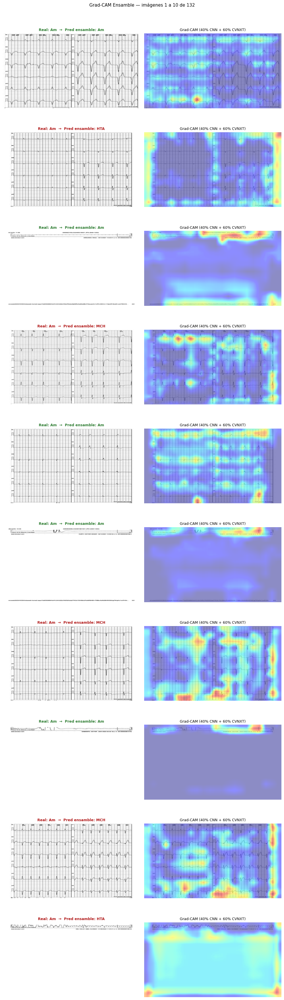

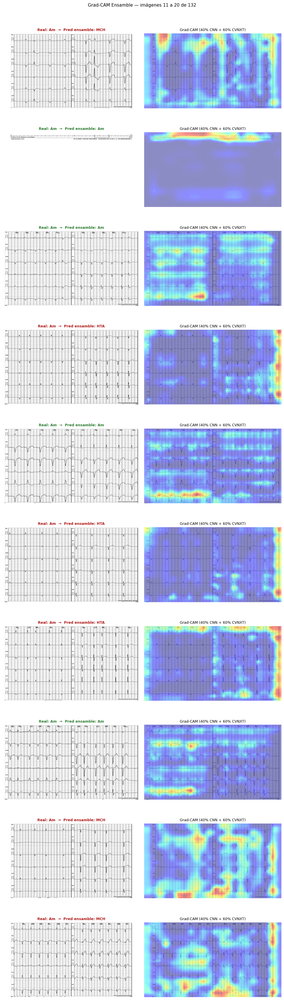

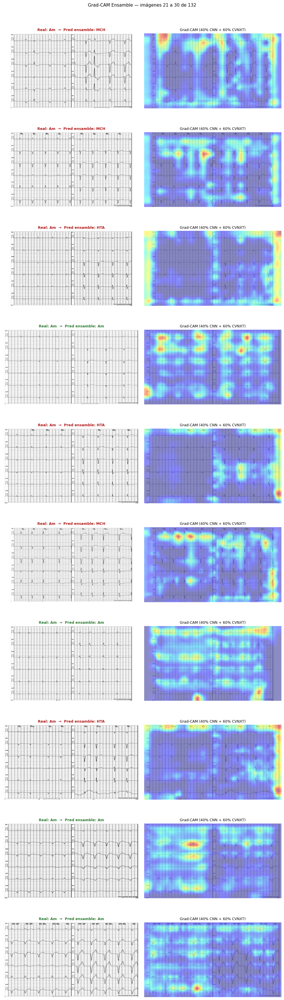

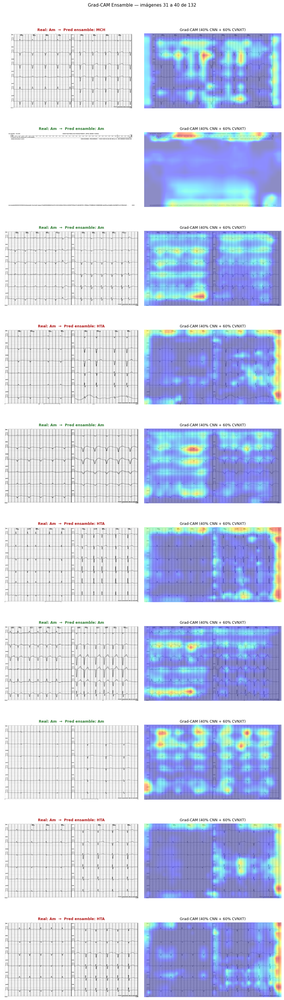

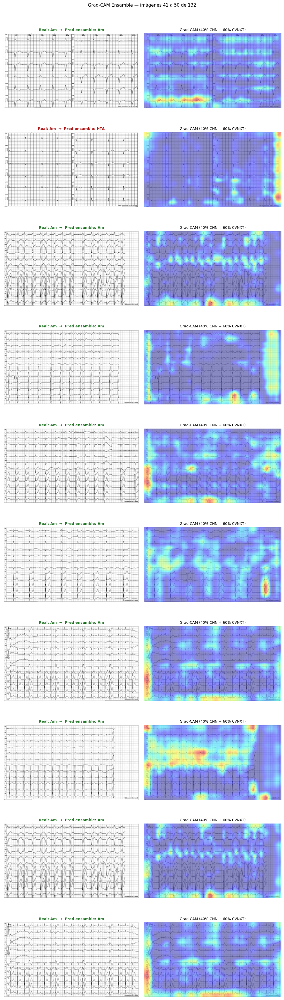

...

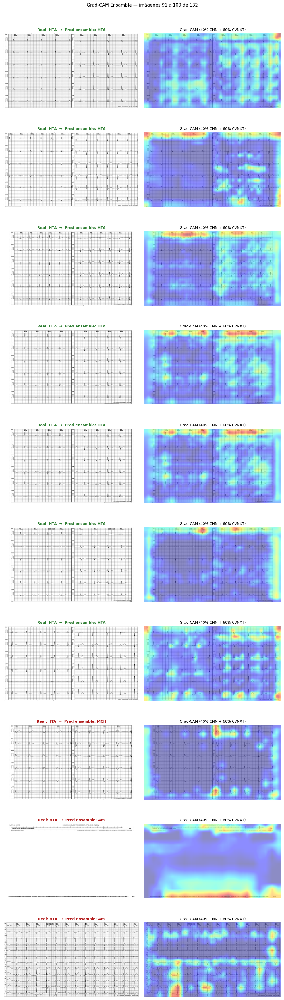

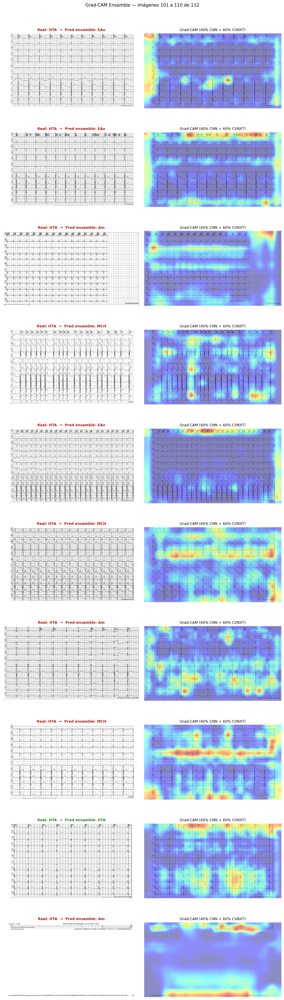

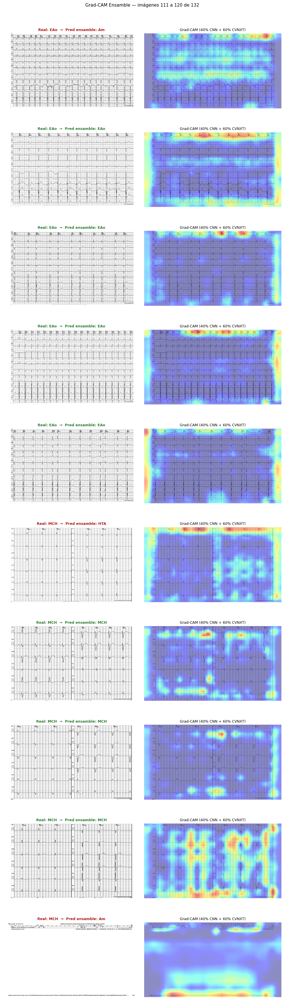

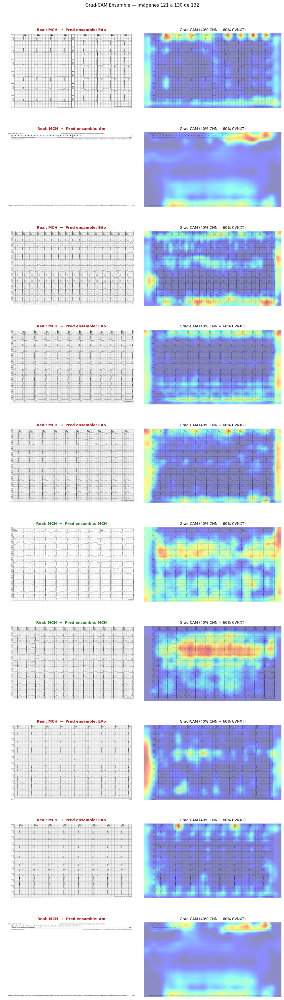

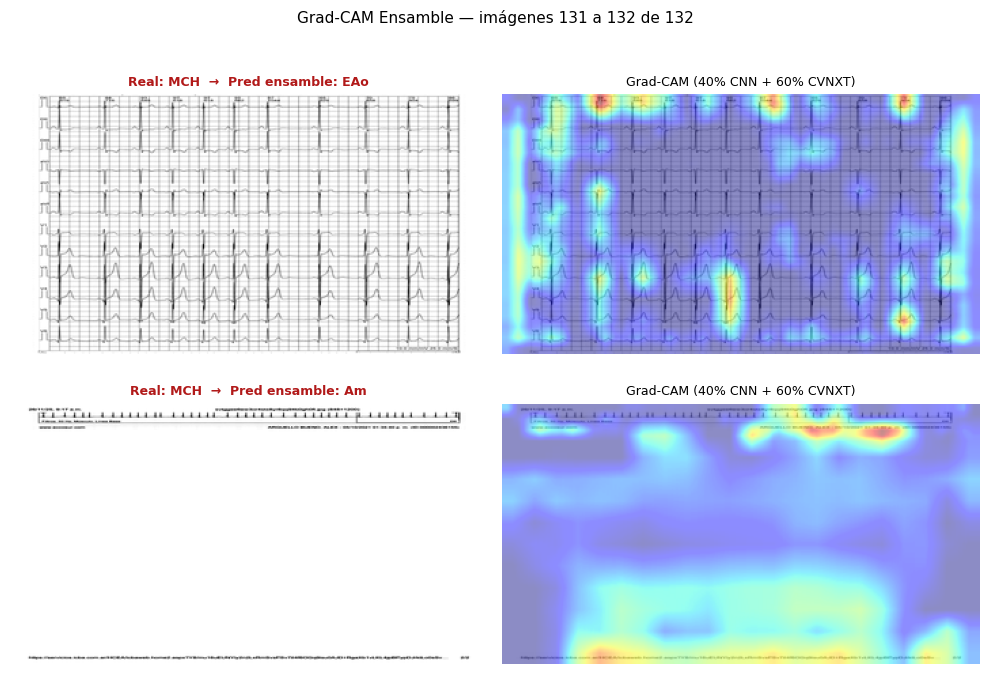

0

In [9]:
model_cnn_gc   = tf.keras.models.load_model(CNN_DIR   / 'CNN-FINAL.keras')
model_cvnxt_gc = tf.keras.models.load_model(CVNXT_DIR / 'CVNXT-FINAL.keras')

grad_model_cnn, grad_model_cvnxt = build_grad_models(
    model_cnn_gc, model_cvnxt_gc, CNN_GRADCAM_LAYER, CVNXT_GRADCAM_LAYER
)

CHUNK = 10
n     = len(imgs_gray)

for chunk_start in range(0, n, CHUNK):
    chunk_end = min(chunk_start + CHUNK, n)
    chunk_n   = chunk_end - chunk_start

    fig, axes = plt.subplots(chunk_n, 2, figsize=(10, 3.5 * chunk_n), squeeze=False)

    for row_i, idx in enumerate(range(chunk_start, chunk_end)):
        gray     = imgs_gray[idx]     # (192, 352, 1) float32
        rgb      = imgs_rgb[idx]      # (192, 352, 3) uint8
        disp     = imgs_disp[idx]     # (192, 352) uint8
        pred_idx = int(ens_preds[idx])
        real_cls = CLASSES[y_true[idx]]
        pred_cls = CLASSES[pred_idx]
        ok       = (y_true[idx] == pred_idx)

        hm_cnn   = compute_gradcam(grad_model_cnn,   gray[np.newaxis], pred_idx)
        hm_cvnxt = compute_gradcam(grad_model_cvnxt, rgb[np.newaxis],  pred_idx)

        # heatmap ensamble ponderado 40/60, renormalizado
        H, W = disp.shape
        hm_cnn_up   = np.array(Image.fromarray((hm_cnn  *255).astype(np.uint8)).resize((W,H), Image.BILINEAR)).astype(np.float32)/255.
        hm_cvnxt_up = np.array(Image.fromarray((hm_cvnxt*255).astype(np.uint8)).resize((W,H), Image.BILINEAR)).astype(np.float32)/255.
        hm_ens = ENSEMBLE_WEIGHTS['cnn']*hm_cnn_up + ENSEMBLE_WEIGHTS['cvnxt']*hm_cvnxt_up
        hm_ens = hm_ens / (hm_ens.max() + 1e-8)

        overlay = overlay_gradcam(disp, hm_ens)

        title_color = '#2e7d32' if ok else '#B11919'
        axes[row_i, 0].imshow(disp, cmap='gray')
        axes[row_i, 0].set_title(f'Real: {real_cls}  →  Pred ensamble: {pred_cls}',
                                  fontsize=9, color=title_color, fontweight='bold')
        axes[row_i, 0].axis('off')

        axes[row_i, 1].imshow(overlay)
        axes[row_i, 1].set_title('Grad-CAM (40% CNN + 60% CVNXT)', fontsize=9)
        axes[row_i, 1].axis('off')

    plt.suptitle(f'Grad-CAM Ensamble — imágenes {chunk_start+1} a {chunk_end} de {n}',
                 fontsize=11, y=1.005)
    plt.tight_layout()
    plt.show()

del model_cnn_gc, model_cvnxt_gc; tf.keras.backend.clear_session(); gc.collect()

Se observa que algunas imágenes presentan problemas en el recorte automático, por lo que la imagen que ingresa al modelo no corresponde únicamente a la región del trazado. En consecuencia, la caída del desempeño observada en estos formatos no puede atribuirse exclusivamente al modelo, sino también a un preprocesamiento. Esto refuerza la decisión de restringir la herramienta al formato 6×2 horizontal y señala que, para extender su uso a otros formatos, sería necesario adaptar tanto el preprocesamiento como el entrenamiento de los modelos.